<table style="border: none !important; border-collapse: collapse; width: 100%;">
<tr style="border: none;">
<td width="260" valign="middle" align="center"
    style="border: none; border-right: 1px solid #777; padding: 25px 40px 25px 15px;">
<img src="logo.png" width="180">
</td>
<td valign="middle"
    style="border: none; padding: 25px 20px 25px 40px;">

<h1 style="font-size: 38px; margin: 0 0 12px 0;">GaLa</h1>

<span style="color:#9670D8; font-weight:600; letter-spacing:3px;">
Gaussian-Asymmetric Laplace Lineshape
</span>

A lightweight toolkit for photoluminescence spectral analysis.

[<span style="color:#9670D8;">PREPRINT ↗</span>](https://www.researchsquare.com/article/rs-8603272/v1)

[<span style="color:#E68A55;">GITHUB ↗</span>](https://github.com/leoluber/gala)

</td>
</tr>
</table>

In [1]:
# Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

# GaLa
from gala.models import GaLa, fastGaLa
from gala.utils import (
    GALA_BOUNDS,
    GALA_P0,
    jacobian_nm_to_eV,
)

## 1. Import and preprocess the spectrum

Load an experimental photoluminescence spectrum from a CSV file using `pandas`.

The input file should contain two columns:
- `wavelength`: emission wavelength in nm (or optional `energy` if already converted)
- `intensity`: measured spectral intensity (counts/nm)

Since the GaLa model is defined on an energy axis, we convert wavelength to photon energy:

$$
E = \frac{hc}{\lambda}
$$

Because this transformation is nonlinear, the spectral intensity must also be transformed using the Jacobian:

$$
I_E = I_\lambda \left|\frac{d\lambda}{dE}\right|
    = I_\lambda \frac{\lambda^2}{hc}
$$

In [2]:
# - load the example data - #

# TODO: the following import may need to be adjusted to your data format
df = pd.read_csv(r"data\examplePL.csv", header = 0, delimiter = ",", names = ["wavelength", "intensity"])

# - transform wavelength to energy & normalize intensity - #
df["energy"], df["intensity"] = jacobian_nm_to_eV(df["wavelength"].values, df["intensity"].values)
df["intensity"] /= np.max(df["intensity"].values)

## 2. Fit the GaLa lineshape

The Gaussian-Asymmetric Laplace (GaLa) lineshape describes the photoluminescence spectrum as the convolution of an approximate inhomogeneous Gaussian distribution with asymmetric thermal tails:

$$
\mathrm{GaLa}(E-E_G,\sigma,w_l,w_h)
\propto
\left(G(\sigma)*T(w_l,w_h)\right)(E-E_G).
$$

The asymmetric tail function is defined as

$$
T(E-E_{se},w_l,w_h)=
\begin{cases}
\exp\left((E-E_{se})/w_l\right),
& E-E_{se}\leq 0,\\
\exp\left(-(E-E_{se})/w_h\right),
& E-E_{se}\geq 0.
\end{cases}
$$

Here, $E_G$ denotes the center of the Gaussian distribution, $\sigma$ its standard deviation, and $w_l$ and $w_h$ the low- and high-energy tail widths, respectively. Energy-independent prefactors are omitted since the spectra are normalized.

The experimental spectrum is fitted using the closed-form implementation `fastGaLa` and `scipy.optimize.curve_fit`.

The fit uses predefined initial parameters (`GALA_P0`) and parameter bounds (`GALA_BOUNDS`). These can be adjusted depending on the spectral range and expected lineshape parameters.

For reliable convergence, the initial guess for the Gaussian center should ideally be set to the spectral maximum:

$$
E_G^{(0)} = E\left(\operatorname{arg\,max}(I_E)\right).
$$

The fitting routine returns the optimized parameters and their estimated covariance matrix. The fitted spectrum is then evaluated using the optimized parameters.

In [3]:
# Set initial peak position to the spectral maximum (optional)
# GALA_P0[0] = df["energy"].iloc[df["intensity"].argmax()]

# Fit GaLa model
popt, pcov = curve_fit(
    fastGaLa,
    df["energy"],
    df["intensity"],
    p0=GALA_P0,
    bounds=GALA_BOUNDS
)

# Evaluate fitted spectrum
fit = fastGaLa(df["energy"], *popt)

\\z-sv-dfs01\dfsroot\project\ag-nanospec\10 - Data\L.Luber\Python\gala\gala\models.py:46: RuntimeWarning: invalid value encountered in multiply
  L = np.exp(-x**2/(2*sigma**2)) * erfcx(


In [ ]:
# Store optimized GaLa parameters
parameters = {
    "E_G": popt[0],       # Gaussian center [eV]
    "sigma": popt[1],     # Gaussian standard deviation [meV]
    "w_h": popt[2],       # High-energy tail width [meV]
    "w_l": popt[3],       # Low-energy tail width [meV]
    "y": popt[4],         # Baseline offset
    "A": popt[5],         # Peak amplitude
}

print(parameters)

{'E_G': np.float64(2.4130276752747832), 'sigma': np.float64(15.599901750209684), 'w_h': np.float64(27.29596638464464), 'w_l': np.float64(39.2849142478332), 'y': np.float64(1.0010065999034283e-19), 'A': np.float64(1.000657814601166)}


## 3. Visualize the fitting results

The fitted GaLa lineshape is compared with the experimental spectrum using both linear and logarithmic intensity scales.

- **Linear scale:** Highlights the peak position, spectral width, and overall agreement between the experimental data and the fitted lineshape.
- **Logarithmic scale:** Emphasizes low-intensity spectral contributions and makes the exponential tails more visible. This provides a more sensitive way to inspect deviations between the model and experimental spectrum, particularly in the spectral wings.

Viewing both representations is useful for assessing the quality of the fit across the entire spectral range, rather than focusing exclusively on the high-intensity peak region.

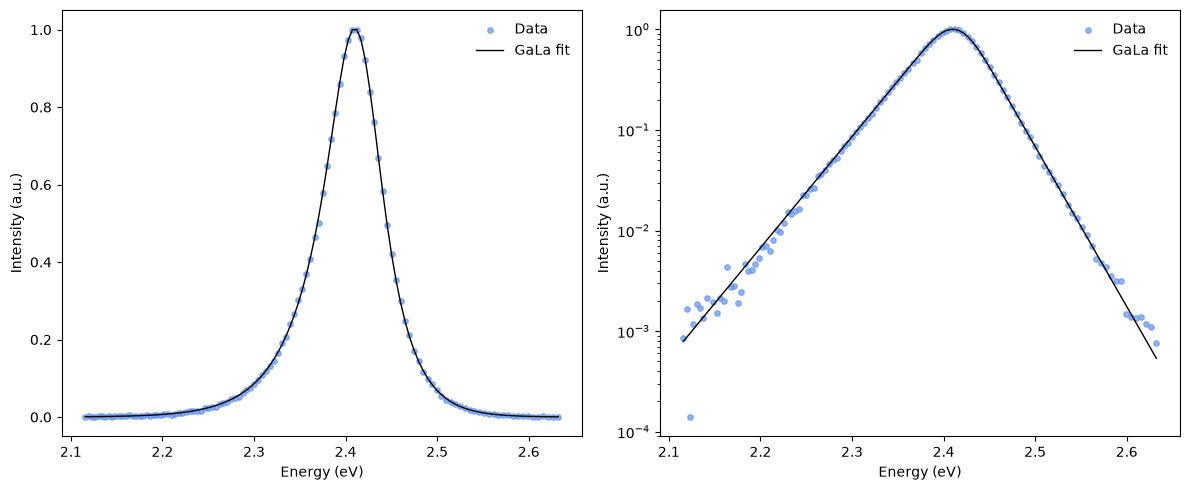

In [5]:
# Plot fitting results
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

for ax, scale in zip(axes, ["linear", "log"]):
    ax.scatter(
        df["energy"], df["intensity"],
        s=15, color="cornflowerblue", alpha=0.7, label="Data"
    )
    ax.plot(df["energy"], fit, color="k", lw=1, label="GaLa fit")

    ax.set_yscale(scale)
    ax.set_xlabel("Energy (eV)")
    ax.set_ylabel("Intensity (a.u.)")
    ax.legend(frameon=False)

plt.tight_layout()
plt.show()

## 4. Fitting a mixed sample

The following example uses a deliberately mixed sample containing a nanocube subpopulation centered at 2.54 eV, with a relative intensity ratio of 1:40, as described in the publication.

The presence of this secondary population is readily detectable through the systematic disagreement between the GaLa fit and the experimental data, particularly in the logarithmic representation.

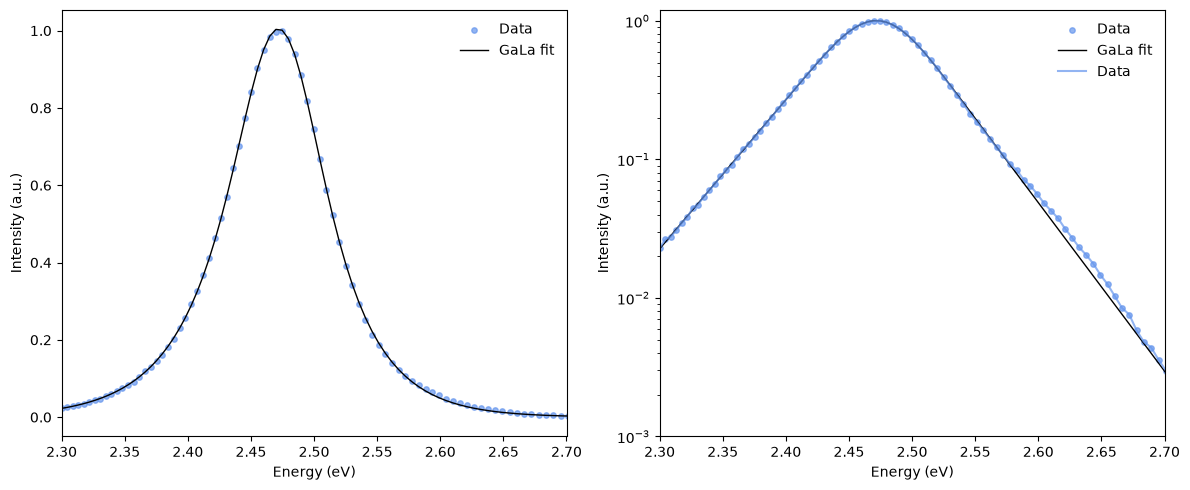

In [52]:
# Load subpopulation spectrum
df_sub = pd.read_csv("data/examplePL_subpopulation.txt", sep=r",", names=["wavelength", "intensity"],)

# Convert wavelength to energy and normalize
df_sub["energy"], df_sub["intensity"] = jacobian_nm_to_eV(df_sub["wavelength"].to_numpy(), df_sub["intensity"].to_numpy())
df_sub["intensity"] /= df_sub["intensity"].max()

# Fit GaLa model
popt_sub, pcov_sub = curve_fit(fastGaLa, df_sub["energy"], df_sub["intensity"], p0=GALA_P0, bounds=GALA_BOUNDS)

fit_sub = fastGaLa(df_sub["energy"], *popt_sub)

# Plot results
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

for ax, scale in zip(axes, ["linear", "log"]):
    ax.scatter(df_sub["energy"], df_sub["intensity"], s=15, color="cornflowerblue", alpha=0.7, label="Data")
    ax.plot(df_sub["energy"], fit_sub, color="k", lw=1, label="GaLa fit")
    ax.set_yscale(scale)
    ax.set_xlabel("Energy (eV)")
    ax.set_ylabel("Intensity (a.u.)")

    if scale == "log":
        ax.plot(df_sub["energy"], df_sub["intensity"], color="cornflowerblue", alpha=0.7, label="Data")
        ax.set_ylim(1e-3, 1.2)
        ax.set_xlim(2.3, 2.7)
    ax.legend(frameon=False)

plt.tight_layout()
plt.show()